# Segmentación de clientes con RFM y K-Means

Este proyecto aplica técnicas de segmentación de clientes sobre el dataset **Online Retail**, que contiene transacciones de una tienda online del Reino Unido.

El objetivo es transformar los datos transaccionales en variables a nivel cliente mediante la metodología **RFM** y posteriormente aplicar **K-Means** para identificar segmentos con patrones de compra distintos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

import warnings
warnings.filterwarnings("ignore")

## 1. Carga del dataset

El dataset contiene información transaccional como número de factura, producto, cantidad, fecha, identificador de cliente y país.

In [2]:
df = pd.read_csv("../data/raw/online_retail.csv", encoding="ISO-8859-1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:
df.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2011-10-31 14:41:00,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


## 2. Exploración inicial

En esta etapa se revisa el tamaño del dataset, los tipos de variables, los valores faltantes y la estructura general antes de realizar el preprocesamiento.

In [6]:
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

CustomerID     135080
Description      1454
dtype: int64

In [7]:
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct[missing_pct > 0]

CustomerID     24.926694
Description     0.268311
dtype: float64

Se observan valores faltantes, principalmente en `CustomerID` y `Description`. Dado que la segmentación requiere identificar clientes, los registros sin `CustomerID` serán eliminados.

## 3. Limpieza de datos

Se aplican las siguientes reglas de limpieza:

- Eliminar filas con `CustomerID` nulo
- Excluir transacciones canceladas
- Eliminar cantidades menores o iguales a cero
- Eliminar precios unitarios menores o iguales a cero

In [8]:
df = df.dropna(subset=["CustomerID"])

In [9]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

In [10]:
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]

In [11]:
df.shape

(397884, 8)

In [12]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 4. Preparación de variables

Para construir indicadores a nivel cliente, la variable de fecha debe convertirse a formato datetime y además se calcula el valor total de cada línea de compra:

`TotalPrice = Quantity × UnitPrice`

In [13]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype(str)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [14]:
df[["Quantity", "UnitPrice", "TotalPrice"]].describe()

,Quantity,UnitPrice,TotalPrice
count,397884.000000,397884.000000,397884.000000
mean,12.988238,3.116488,22.397000
std,179.331775,22.097877,309.071041
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.680000
50%,6.000000,1.950000,11.800000
75%,12.000000,3.750000,19.800000
max,80995.000000,8142.750000,168469.600000


## 5. Distribuciones numéricas a nivel transacción

Antes de construir la tabla RFM, se analizan las distribuciones de las variables numéricas transaccionales para detectar sesgo y posibles valores extremos.

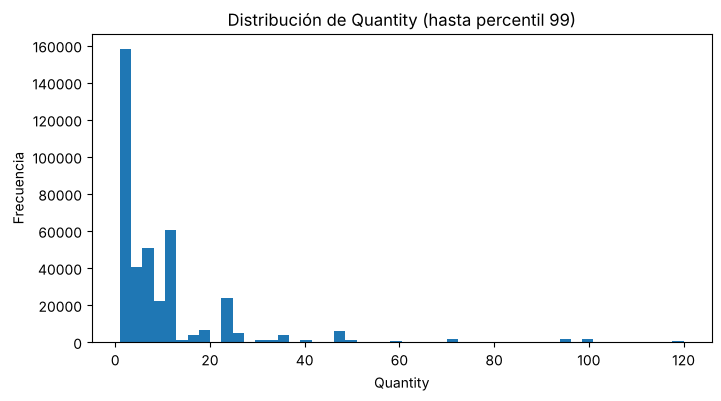

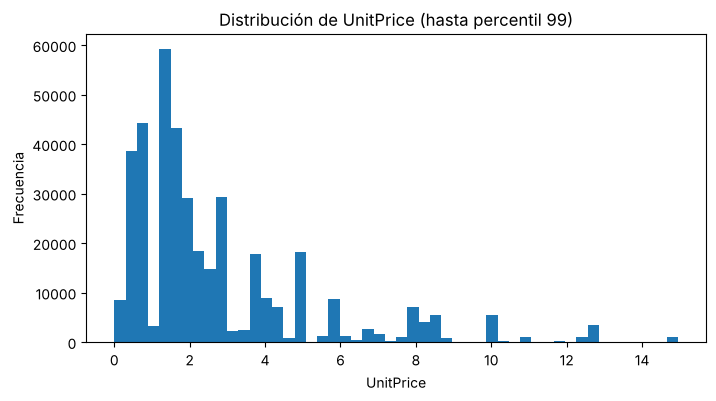

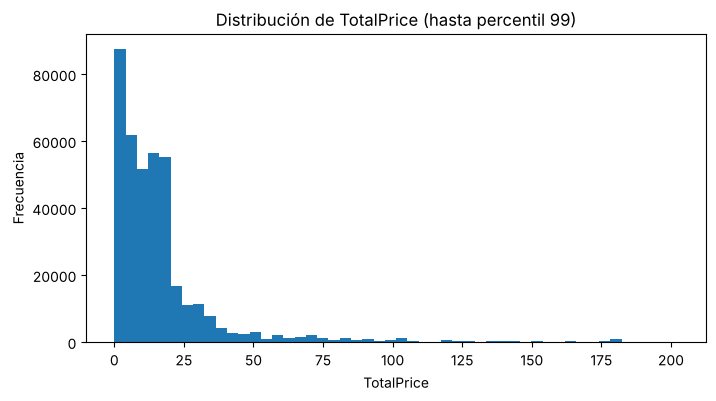

In [15]:
numeric_cols = ["Quantity", "UnitPrice", "TotalPrice"]

for col in numeric_cols:
    upper = df[col].quantile(0.99)
    
    plt.figure(figsize=(8,4))
    plt.hist(df[df[col] <= upper][col], bins=50)
    plt.title(f"Distribución de {col} (hasta percentil 99)")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

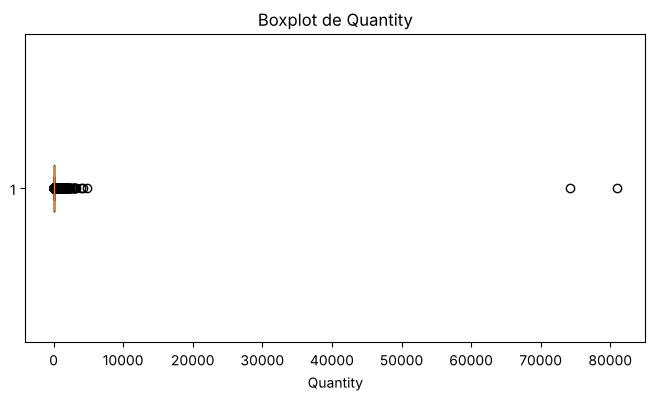

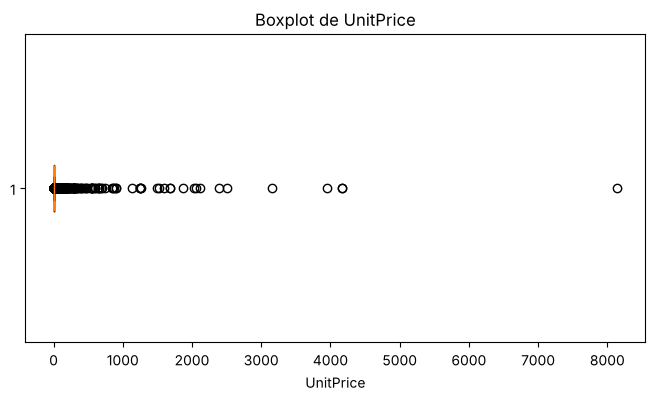

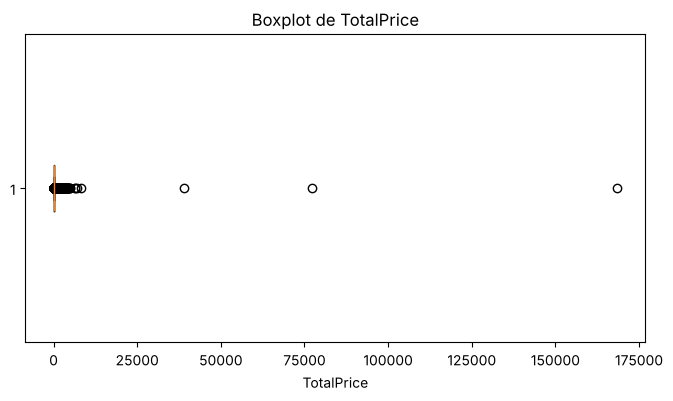

In [16]:
for col in numeric_cols:
    plt.figure(figsize=(8,4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

Las distribuciones presentan un fuerte sesgo a la derecha, algo esperable en datos transaccionales de retail. Un pequeño grupo de observaciones concentra valores considerablemente mayores que la mayoría.

## 6. Construcción de variables RFM

La segmentación se realiza a nivel cliente, no a nivel transacción. Por ello, los datos se agregan en tres indicadores clave:

- **Recency**: días desde la última compra
- **Frequency**: número de compras o facturas únicas
- **Monetary**: gasto total acumulado

In [17]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
snapshot_date

Timestamp('2011-12-10 12:50:00')

In [18]:
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
}).reset_index()

In [19]:
rfm.columns = ["CustomerID", "Recency", "Frequency", "Monetary"]
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [20]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


## 7. Análisis de distribución de RFM

Las variables RFM suelen presentar asimetría y valores extremos. Para evaluarlo, se revisan tanto histogramas como boxplots, ya que estas características pueden afectar negativamente el desempeño de K-Means si no se tratan adecuadamente.

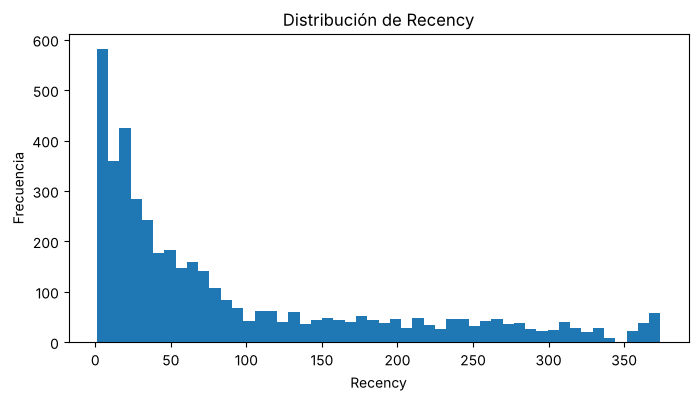

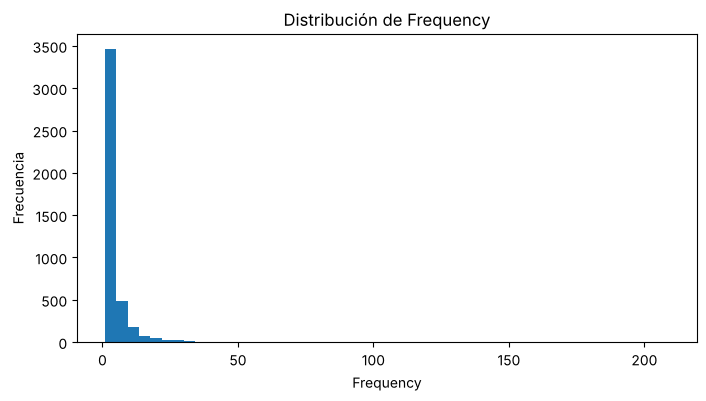

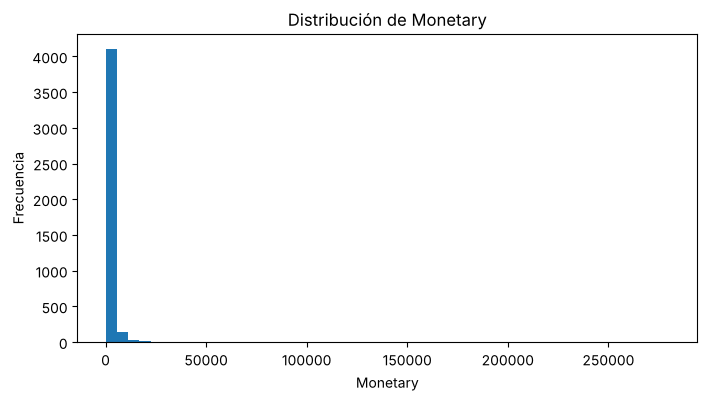

In [21]:
rfm_cols = ["Recency", "Frequency", "Monetary"]

for col in rfm_cols:
    plt.figure(figsize=(8,4))
    plt.hist(rfm[col], bins=50)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

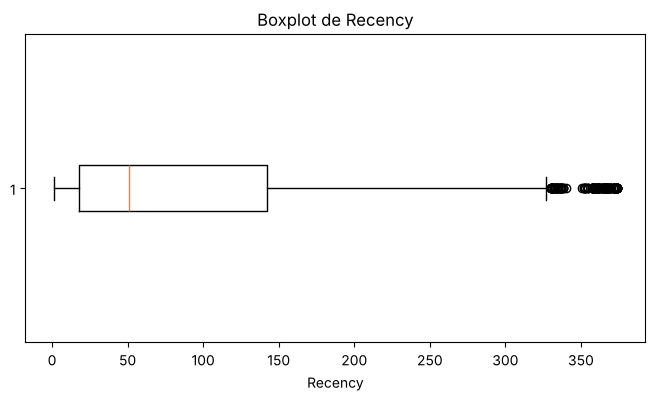

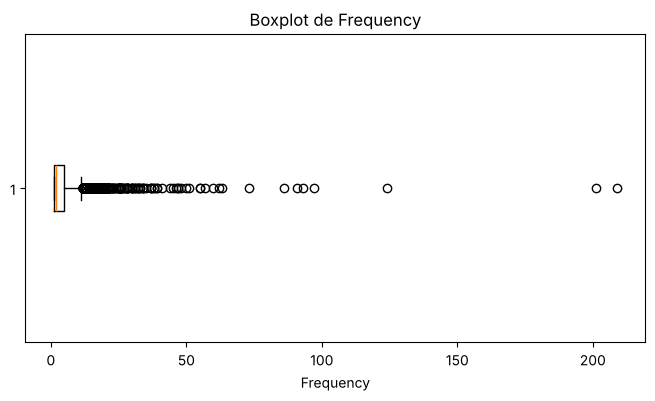

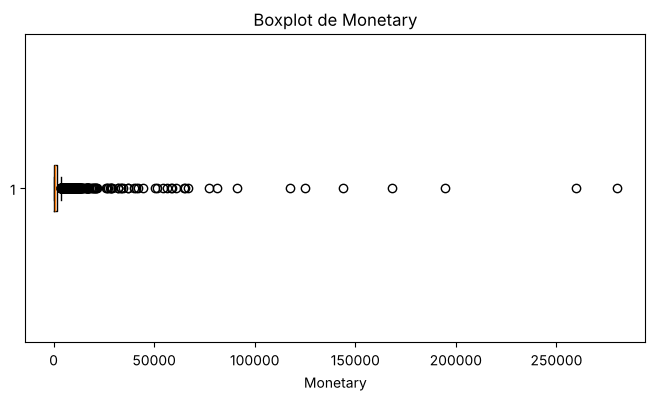

In [22]:
for col in rfm_cols:
    plt.figure(figsize=(8,4))
    plt.boxplot(rfm[col], vert=False)
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

## 8. Transformación logarítmica

Dado que `Frequency` y `Monetary` suelen estar altamente sesgadas, se aplica una transformación logarítmica para reducir el efecto de los valores extremos y mejorar la calidad del clustering.

In [23]:
rfm_log = rfm.copy()

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

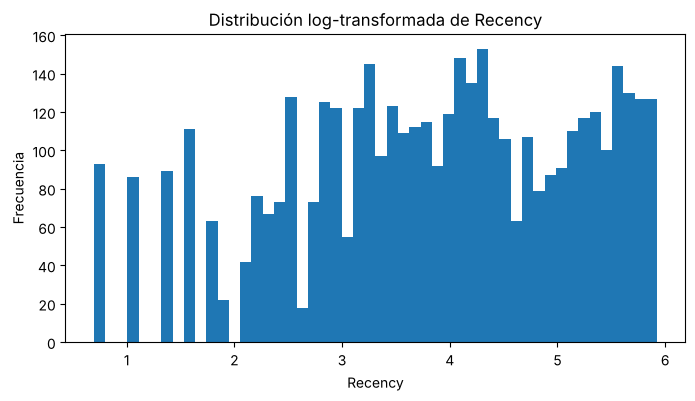

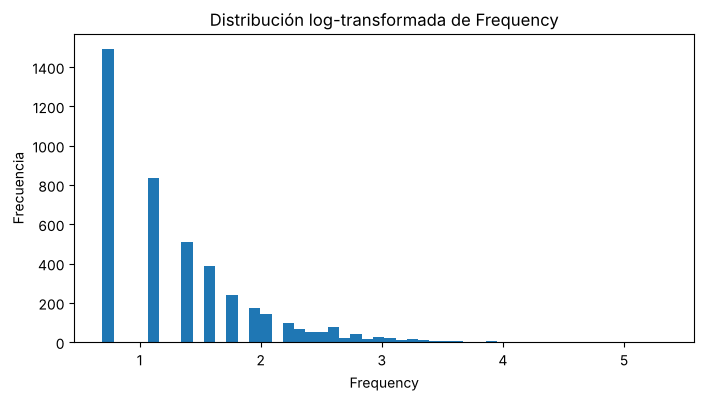

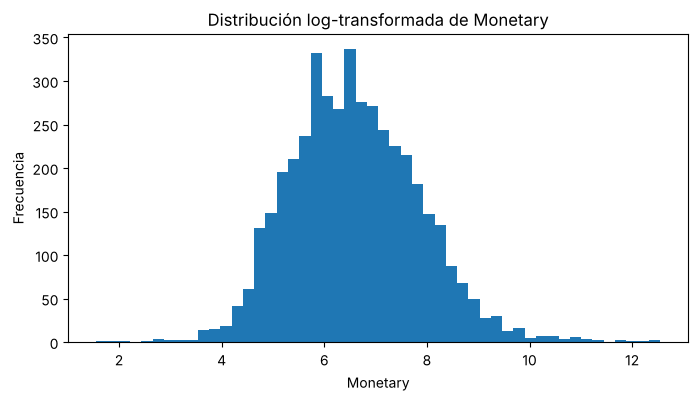

In [24]:
for col in rfm_cols:
    plt.figure(figsize=(8,4))
    plt.hist(rfm_log[col], bins=50)
    plt.title(f"Distribución log-transformada de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

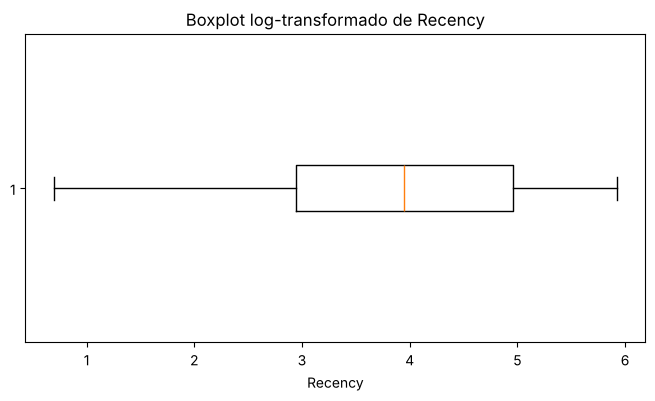

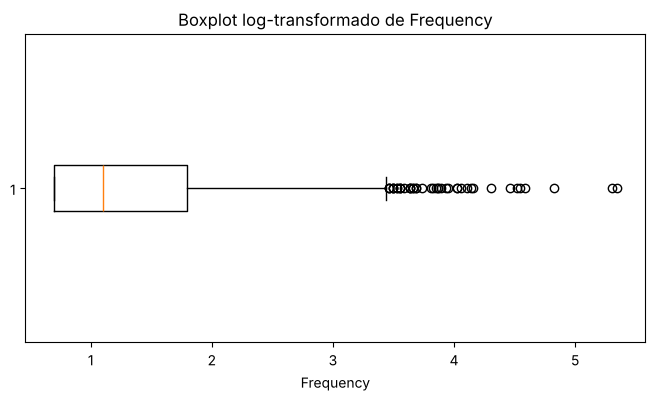

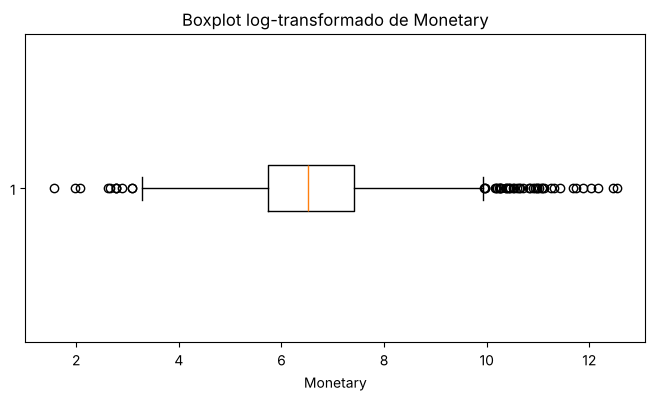

In [25]:
for col in rfm_cols:
    plt.figure(figsize=(8,4))
    plt.boxplot(rfm_log[col], vert=False)
    plt.title(f"Boxplot log-transformado de {col}")
    plt.xlabel(col)
    plt.show()

## 9. Escalamiento de variables

K-Means es un algoritmo basado en distancias, por lo que es necesario estandarizar las variables para evitar que una dimensión domine el proceso de agrupamiento por tener una escala mayor.

In [26]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log[["Recency", "Frequency", "Monetary"]])

In [27]:
rfm_scaled[:5]

array([[ 1.46199281, -0.95521426,  3.70622476],
       [-2.03873442,  1.07442519,  1.41184341],
       [ 0.37310424,  0.38630445,  0.7164889 ],
       [-0.62308592, -0.95521426,  0.6987394 ],
       [ 1.42455753, -0.95521426, -0.6189622 ]])

## 10. Selección del número de clusters

Para determinar el número más adecuado de grupos, se utiliza primero el método del codo, que evalúa cómo disminuye la suma de cuadrados intra-cluster a medida que aumenta `k`.

In [28]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled)
    wcss.append(model.inertia_)

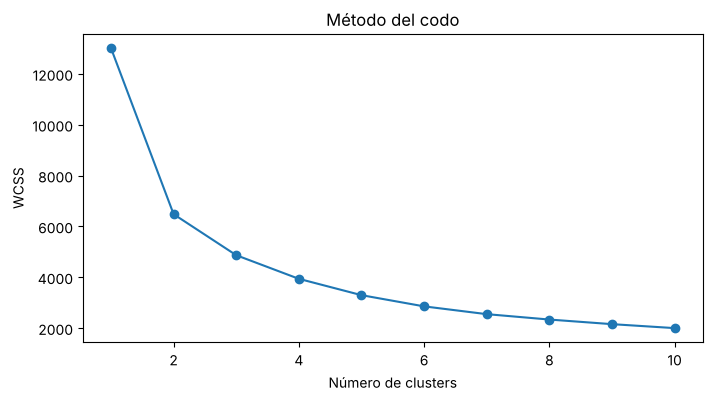

In [29]:
plt.figure(figsize=(8,4))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clusters")
plt.ylabel("WCSS")
plt.show()

Para complementar el método del codo, también se utiliza el **Silhouette Score**, que permite evaluar qué tan bien separados están los clusters entre sí.

In [30]:
sil_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    sil_scores.append(score)

sil_table = pd.DataFrame({"k": list(range(2, 11)), "silhouette": sil_scores}).round(4)
print(sil_table.to_string(index=False))


 k  silhouette
 2      0.4329
 3      0.3365
 4      0.3371
 5      0.3161
 6      0.3133
 7      0.3100
 8      0.3008
 9      0.2817
10      0.2787


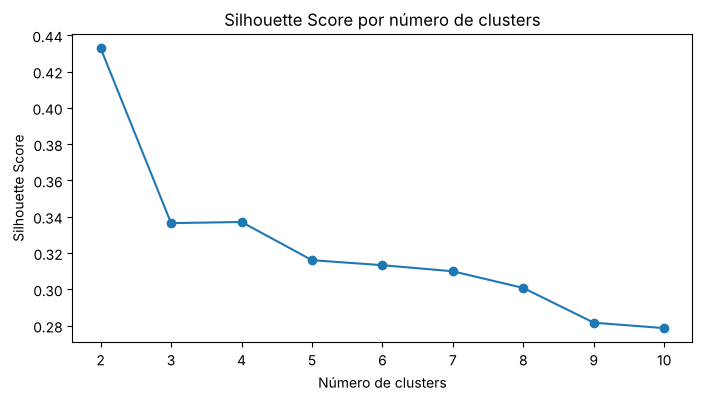

In [31]:
plt.figure(figsize=(8,4))
plt.plot(range(2, 11), sil_scores, marker="o")
plt.title("Silhouette Score por número de clusters")
plt.xlabel("Número de clusters")
plt.ylabel("Silhouette Score")
plt.show()

### Elección de `k = 4`

El Silhouette Score más alto corresponde a `k = 2` (0,4329), no a `k = 4` (0,3371). Aun así se elige `k = 4`, por interpretabilidad y no por la métrica:

- Con `k = 2` los clientes se dividen en dos grandes grupos. Es la partición mejor separada, pero demasiado gruesa para diseñar acciones de marketing diferenciadas.
- Entre `k = 3` y `k = 6` el silhouette varía poco (de 0,3365 a 0,3133) y después sigue bajando. `k = 4` (0,3371) es prácticamente igual a `k = 3` (0,3365) y entrega cuatro perfiles con una lectura de negocio distinta cada uno, que se describen más abajo.
- La curva del codo no muestra un quiebre nítido, por lo que no zanja la elección por sí sola.

Un silhouette cercano a 0,34 indica una separación moderada: los segmentos son cortes útiles sobre un continuo de comportamiento, no grupos naturales claramente aislados. Las fronteras entre segmentos deben leerse con esa cautela.


In [32]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,2
1,12347.0,2,7,4310.00,1
2,12348.0,75,4,1797.24,2
3,12349.0,19,1,1757.55,0
4,12350.0,310,1,334.40,3


## 11. Perfilamiento de clusters

Una vez asignados los clusters, se analizan los valores promedio de RFM en cada grupo para comprender el comportamiento de los clientes segmentados.

Dado que las variables tienen escalas distintas, también se utiliza una visualización estandarizada para comparar mejor los perfiles relativos entre clusters.

In [33]:
cluster_summary = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2)
cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,18.12,2.15,551.82
1,12.13,13.71,8074.27
2,71.08,4.08,1802.83
3,182.50,1.32,343.45


In [34]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()
cluster_counts

Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

In [35]:
cluster_summary["Count"] = cluster_counts
cluster_summary

,Recency,Frequency,Monetary,Count
Cluster,,,,
0,18.12,2.15,551.82,837
1,12.13,13.71,8074.27,716
2,71.08,4.08,1802.83,1173
3,182.50,1.32,343.45,1612


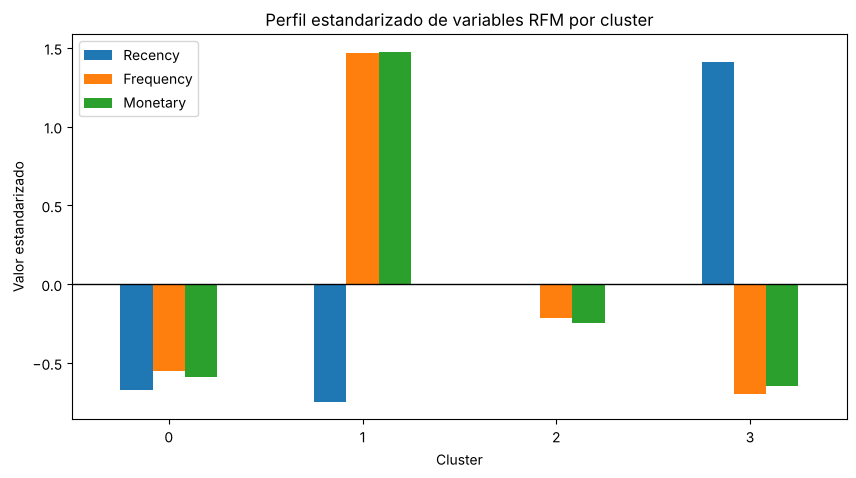

In [36]:
cluster_profile_std = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()
cluster_profile_std = (cluster_profile_std - cluster_profile_std.mean()) / cluster_profile_std.std()

cluster_profile_std.plot(kind="bar", figsize=(10,5))
plt.title("Perfil estandarizado de variables RFM por cluster")
plt.ylabel("Valor estandarizado")
plt.xticks(rotation=0)
plt.axhline(0, color="black", linewidth=1)
plt.show()

## 12. Visualización de clusters con PCA

Como el clustering se realiza en un espacio multidimensional, se utiliza PCA para proyectar las variables estandarizadas en dos dimensiones y facilitar su visualización.

Además, se revisa la proporción de varianza explicada por los dos primeros componentes para interpretar con mayor cautela esta representación bidimensional.

In [37]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_)
print("Varianza explicada acumulada:", pca.explained_variance_ratio_.sum())

Varianza explicada por PC1 y PC2: [0.75102042 0.18759201]
Varianza explicada acumulada: 0.9386124314129808


In [38]:
pca_df = pd.DataFrame(rfm_pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = rfm["Cluster"].values
pca_df.head()

,PC1,PC2,Cluster
0,0.872658,2.686758,2
1,2.550260,-0.804427,1
2,0.475142,0.746121,2
3,0.145832,-0.460480,0
4,-1.688990,0.676555,3


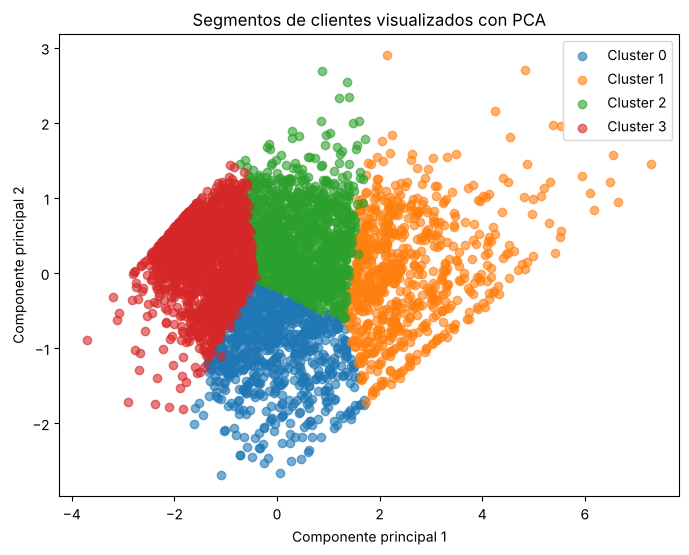

In [39]:
plt.figure(figsize=(8,6))

for cluster in sorted(pca_df["Cluster"].unique()):
    subset = pca_df[pca_df["Cluster"] == cluster]
    plt.scatter(subset["PC1"], subset["PC2"], label=f"Cluster {cluster}", alpha=0.6)

plt.title("Segmentos de clientes visualizados con PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.show()

## 13. Interpretación de negocio

Para que la segmentación sea útil desde un punto de vista empresarial, cada cluster debe interpretarse según su perfil RFM observado.

La asignación de nombres no depende del número del cluster, sino de los valores promedio de recencia, frecuencia y gasto de cada grupo.

In [40]:
cluster_summary

,Recency,Frequency,Monetary,Count
Cluster,,,,
0,18.12,2.15,551.82,837
1,12.13,13.71,8074.27,716
2,71.08,4.08,1802.83,1173
3,182.50,1.32,343.45,1612


In [41]:
# Los nombres se asignan según el perfil de cada cluster y no según su número,
# porque la numeración de K-Means es arbitraria y puede cambiar entre ejecuciones.
profile = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()

vip = profile["Monetary"].idxmax()
en_riesgo = profile["Recency"].idxmax()
restantes = profile.drop(index=[vip, en_riesgo]).sort_values("Recency")
recientes, regulares = restantes.index

segment_map = {
    vip: "Clientes VIP",
    regulares: "Clientes regulares o potencialmente leales",
    recientes: "Clientes recientes de bajo valor",
    en_riesgo: "Clientes en riesgo",
}

rfm["Segmento"] = rfm["Cluster"].map(segment_map)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,Segmento
0,12346.0,326,1,77183.60,2,Clientes regulares o potencialmente leales
1,12347.0,2,7,4310.00,1,Clientes VIP
2,12348.0,75,4,1797.24,2,Clientes regulares o potencialmente leales
3,12349.0,19,1,1757.55,0,Clientes recientes de bajo valor
4,12350.0,310,1,334.40,3,Clientes en riesgo


In [42]:
cluster_summary.sort_values(by="Monetary", ascending=False)

,Recency,Frequency,Monetary,Count
Cluster,,,,
1,12.13,13.71,8074.27,716
2,71.08,4.08,1802.83,1173
0,18.12,2.15,551.82,837
3,182.50,1.32,343.45,1612


In [43]:
cluster_summary.sort_values(by=["Recency", "Frequency", "Monetary"], ascending=[True, False, False])

,Recency,Frequency,Monetary,Count
Cluster,,,,
1,12.13,13.71,8074.27,716
0,18.12,2.15,551.82,837
2,71.08,4.08,1802.83,1173
3,182.50,1.32,343.45,1612


### Perfil de cada segmento

La tabla resume cada segmento: cuántos clientes tiene, qué parte del ingreso total concentra y sus valores típicos de RFM. Se muestran medianas además del gasto medio, porque el gasto tiene valores extremos que arrastran el promedio.

In [44]:
grouped = rfm.groupby("Segmento")

segment_profile = pd.DataFrame(
    {
        "Clientes": grouped.size(),
        "% de clientes": (grouped.size() / len(rfm) * 100).round(1),
        "% del ingreso": (grouped["Monetary"].sum() / rfm["Monetary"].sum() * 100).round(1),
        "Recencia mediana (días)": grouped["Recency"].median(),
        "Frecuencia mediana (facturas)": grouped["Frequency"].median(),
        "Gasto mediano (£)": grouped["Monetary"].median().round(2),
        "Gasto medio (£)": grouped["Monetary"].mean().round(2),
    }
).sort_values("% del ingreso", ascending=False)

segment_profile

,Clientes,% de clientes,% del ingreso,Recencia mediana (días),Frecuencia mediana (facturas),Gasto mediano (£),Gasto medio (£)
Segmento,,,,,,,
Clientes VIP,716,16.5,64.9,8.0,10.0,3733.87,8074.27
Clientes regulares o potencialmente leales,1173,27.0,23.7,56.0,4.0,1345.62,1802.83
Clientes en riesgo,1612,37.2,6.2,177.0,1.0,298.26,343.45
Clientes recientes de bajo valor,837,19.3,5.2,17.0,2.0,471.70,551.82


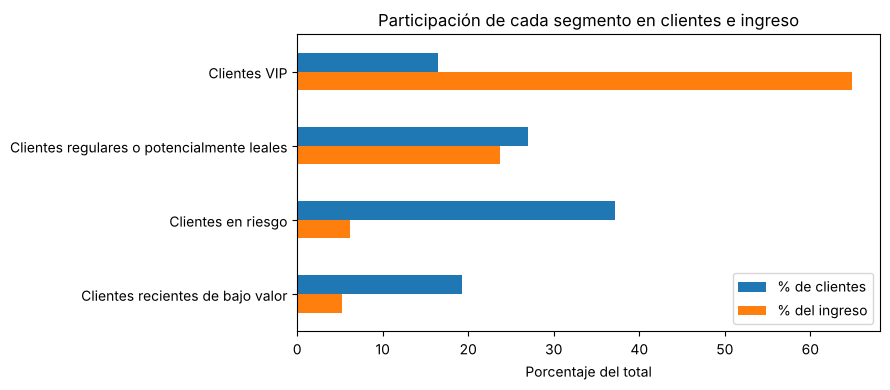

In [45]:
ax = segment_profile[["% de clientes", "% del ingreso"]].plot(kind="barh", figsize=(9, 4))
ax.invert_yaxis()
ax.set_xlabel("Porcentaje del total")
ax.set_ylabel("")
ax.set_title("Participación de cada segmento en clientes e ingreso")
plt.tight_layout()
plt.savefig("../figures/segmentos_clientes_ingreso.png", dpi=150)
plt.show()

### Acción de marketing por segmento

| Segmento | Qué lo caracteriza | Acción propuesta | Cómo medirla |
|---|---|---|---|
| **Clientes VIP** | El 16,5 % de los clientes genera el 64,9 % del ingreso. Compran con frecuencia (mediana de 10 facturas) y hace poco (8 días). | Retención prioritaria: atención preferente, acceso anticipado a productos y alertas si su frecuencia cae. No conviene darles descuentos generales, porque ya compran. | Tasa de recompra a 90 días y gasto por cliente. |
| **Regulares o potencialmente leales** | 27,0 % de los clientes y 23,7 % del ingreso. Compran varias veces, pero su última compra fue hace unos dos meses (mediana de 56 días). | Aumentar la frecuencia: recomendaciones basadas en compras anteriores y un programa de puntos que premie la siguiente compra. | Paso de clientes a VIP y días entre compras. |
| **Recientes de bajo valor** | 19,3 % de los clientes y 5,2 % del ingreso. Compraron hace poco (17 días), pero solo una o dos veces y por montos bajos. | Conseguir la segunda y tercera compra: secuencia de bienvenida y un incentivo acotado a la próxima compra. | Porcentaje que hace otra compra en 60 días. |
| **En riesgo** | El grupo más grande (37,2 % de los clientes) y solo el 6,2 % del ingreso. Una sola compra, hace unos seis meses (177 días). | Reactivación de bajo costo (correo con oferta) y, si no responden, dejar de invertir en ellos. | Tasa de reactivación y costo por cliente reactivado. |

Estas acciones son hipótesis derivadas del perfil RFM. El dataset no incluye campañas ni costos, así que no se puede estimar su efecto: habría que probarlas con un grupo de control.

## 13.1 Estabilidad de la segmentación

K-Means parte de centros aleatorios y agrupa lo que haya en los datos, existan o no grupos reales. Antes de usar los segmentos conviene comprobar que no dependen del azar. Se hacen dos pruebas y en ambas se compara cada resultado con la segmentación de referencia mediante el **índice de Rand ajustado** (ARI): 1 significa la misma partición y 0 un acuerdo no mayor al esperado por azar.

1. **Semillas distintas**: se repite K-Means con 20 semillas sobre todos los clientes.
2. **Submuestras**: se repite sobre 20 muestras aleatorias del 80 % de los clientes y se compara la asignación de los clientes incluidos.

Se calcula para k de 2 a 5, para ver cuánto cuesta en estabilidad pasar de 2 a 4 segmentos.

In [46]:
N_REPETICIONES = 20
rng = np.random.default_rng(42)

rows = []
for k in range(2, 6):
    referencia = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(rfm_scaled)

    ari_semillas = [
        adjusted_rand_score(
            referencia,
            KMeans(n_clusters=k, random_state=semilla, n_init=10).fit_predict(rfm_scaled),
        )
        for semilla in range(N_REPETICIONES)
    ]

    ari_submuestras = []
    for _ in range(N_REPETICIONES):
        indices = rng.choice(len(rfm_scaled), size=int(0.8 * len(rfm_scaled)), replace=False)
        etiquetas = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(rfm_scaled[indices])
        ari_submuestras.append(adjusted_rand_score(referencia[indices], etiquetas))

    rows.append(
        {
            "k": k,
            "ARI semillas (media)": np.mean(ari_semillas),
            "ARI semillas (mínimo)": np.min(ari_semillas),
            "ARI submuestras (media)": np.mean(ari_submuestras),
            "ARI submuestras (mínimo)": np.min(ari_submuestras),
        }
    )

stability = pd.DataFrame(rows).set_index("k").round(3)
stability

,ARI semillas (media),ARI semillas (mínimo),ARI submuestras (media),ARI submuestras (mínimo)
k,,,,
2,1.000,0.998,0.989,0.939
3,0.986,0.948,0.965,0.918
4,0.971,0.942,0.950,0.819
5,0.938,0.883,0.878,0.757


**Lectura.**

- Con `k = 4` la segmentación es razonablemente estable: el ARI medio es 0,971 al cambiar la semilla (mínimo 0,942) y 0,950 al repetir sobre submuestras del 80 % (mínimo 0,819). La gran mayoría de los clientes cae siempre en el mismo segmento; los que cambian son los que están cerca de la frontera entre dos grupos.
- La estabilidad baja a medida que aumenta `k`. Con `k = 2` la partición es casi idéntica en todas las repeticiones (0,989 en submuestras) y con `k = 5` se degrada de forma visible (0,878 de media y 0,757 en el peor caso).
- Pasar de 3 a 4 segmentos cuesta poco (de 0,965 a 0,950 en submuestras), lo que respalda quedarse con `k = 4`; ir a 5 ya no se justifica.

El resultado es coherente con el silhouette moderado: los segmentos son reproducibles, pero sus fronteras son difusas. Para decisiones sobre clientes individuales cerca de una frontera conviene mirar sus valores de RFM y no solo la etiqueta.

## 14. Exportación de resultados

La tabla RFM procesada y la segmentación final de clientes se exportan para su uso posterior en dashboards o análisis de negocio.

In [47]:
rfm.to_csv("../data/processed/customer_segments.csv", index=False)
cluster_summary.to_csv("../data/processed/rfm_table.csv", index=False)

## 15. Conclusión

Este proyecto transformó datos transaccionales en segmentos de clientes accionables mediante el uso de variables RFM y clustering con K-Means.

La segmentación permitió identificar diferencias relevantes en el comportamiento de compra según la antigüedad de la última compra, la frecuencia y el gasto acumulado. Estos grupos pueden servir para apoyar decisiones como:

- campañas de retención para clientes valiosos
- estrategias de reactivación para clientes inactivos
- acciones de marketing personalizadas para compradores ocasionales
- programas de fidelización para clientes frecuentes

El hallazgo más útil es la concentración del ingreso: el 16,5 % de los clientes (segmento VIP) genera el 64,9 % del gasto, mientras que el segmento más numeroso (en riesgo, 37,2 % de los clientes) aporta el 6,2 %.

La segmentación es estable ante cambios de semilla y de muestra, pero la separación entre grupos es moderada (silhouette de 0,34) y las acciones propuestas son hipótesis: su efecto no se puede medir con este dataset y habría que validarlo con una campaña y un grupo de control.